# Phase I · Radar input & error explorer

**Question:** what do the model's actual radar inputs look like for frames it gets right and frames it gets wrong at a *similar* ground-truth (GT) speed?

**Data:** `results/phase1/main_0/bot_beckman_5thfloor_1_matched_cases.npz` contains 10 real frames in 5 pairs (one low-error and one high-error frame each), with both input channels (`radar_d`, `radar_de`). Frames 546–559, the suspected GT anomaly, were excluded when the pairs were selected.

**Outputs** (next to the data file):
- `bot_beckman_5thfloor_1_radar_error_explorer.html`: interactive explorer.
- `bot_beckman_5thfloor_1_radar_comparison.png`: static 1920×1080 figure for the video.

**Scope (Phase I, black box):**
- Only inputs and outputs are compared: no saliency, Grad-CAM or internal activations.
- Visible differences between inputs are *observations*. They do not show what caused an error or what the network attends to.
- The pairs were **selected by their errors**, so they are exploratory examples, not a representative sample.

**How to use the explorer:**
- Choose a pair in the *Frame pair* menu, or click a row in the overview. Pair 3 is shown first.
- Pairs 1–3 are the preferred examples. Pairs 4–5 stay selectable, but their lateral GT velocities differ more.
- Each channel (one heatmap row) uses **one fixed 0–1 colour scale** for both frames and every pair, with its own colourbar.
- **Compare colours within a row only.** The two channels are preprocessed differently, so the same colour in the two rows does not mean the same signal (section 5).
- Heatmap axes are **bin indices** as stored in the model input: rows are Doppler bins and columns are azimuth bins. Physical units are not verified here.
- All numbers are computed at full precision and rounded to 3 decimals only for display (section 4).

**Requires:** the RadaVis Python 3.11 environment with `numpy`, `pandas`, `altair` (≥ 5.4; tested with 6.0.0) and `matplotlib`, plus **`vl-convert-python==1.9.0.post1`**. That package embeds the Vega JavaScript, so the HTML opens without internet. The first code cell stops with the install command if the package is missing or has another version. There is no fallback to an HTML that loads Vega from the internet.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import base64
import os
import re
import struct
import warnings
import zlib

import numpy as np
import pandas as pd

try:
    import altair as alt
except ImportError as e:
    raise ImportError('Altair is missing. In the RadaVis environment run:  python -m pip install "altair==6.0.0"') from e
if not hasattr(alt, "when"):
    raise ImportError(f'Altair {alt.__version__} is too old for this notebook; run:  python -m pip install "altair==6.0.0"')

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.lines import Line2D
import matplotlib.ticker as mticker

# The HTML must open offline, so the Vega JavaScript is embedded by vl-convert-python (exact tested version).
VL_CONVERT_PIN = "1.9.0.post1"


def require_vl_convert() -> str:
    # Stop with the install command unless exactly the pinned vl-convert-python is installed.
    try:
        installed = version("vl-convert-python")
    except PackageNotFoundError:
        installed = None
    if installed != VL_CONVERT_PIN:
        found = "it is not installed" if installed is None else f"version {installed} is installed"
        raise ImportError(
            f"The offline HTML export needs vl-convert-python=={VL_CONVERT_PIN}, but {found}.\n"
            "Install it in the RadaVis Python 3.11 environment, restart the kernel and run all cells again:\n"
            f'    python -m pip install "vl-convert-python=={VL_CONVERT_PIN}"')
    import vl_convert  # noqa: F401  (fails here if the installation is broken)
    return installed


print("numpy", np.__version__, "| pandas", pd.__version__, "| altair", alt.__version__,
      "| matplotlib", matplotlib.__version__, "| vl-convert-python", require_vl_convert())

numpy 1.26.4 | pandas 2.2.3 | altair 6.0.0 | matplotlib 3.10.7 | vl-convert-python 1.9.0.post1


## 1 · Configuration
All paths are relative to the RadaVis project root, which is found by walking up from this notebook's folder.

In [2]:
SEQUENCE = "bot_beckman_5thfloor_1"
SPLIT = "main_0"                     # checkpoint output_main_0/transnet18 (sequence is held out in this split)
DEFAULT_PAIR = 3                     # pair shown first in the explorer
STATIC_PAIR = 3                      # pair shown in the static PNG
PREFERRED_PAIRS = (1, 2, 3)          # pairs 4-5: larger difference in lateral GT velocity
EXPECTED_PAIRS = {                   # pair -> (low-error frame, high-error frame), from the selection notes
    1: (192, 386), 2: (1681, 667), 3: (656, 1050), 4: (1676, 1378), 5: (188, 62),
}
SUSPECT_FRAMES = (546, 559)          # suspected GT anomaly; must not appear in the selection
CHANNELS = ("radar_d", "radar_de")   # model input order: [radar_d, radar_de]
COLOR_DOMAIN = (0.0, 1.0)            # fixed colour scale, compared within each channel only (section 5)


def find_repo_root(start: Path) -> Path:
    # Walk up to the RadaVis root (the folder holding results/ and notebooks/).
    for p in [start, *start.parents]:
        if (p / "results").is_dir() and (p / "notebooks").is_dir():
            return p
    raise FileNotFoundError("RadaVis root not found above %s" % start)


ROOT = find_repo_root(Path.cwd().resolve())
OUT_DIR = ROOT / "results" / "phase1" / SPLIT
CASES_PATH = OUT_DIR / f"{SEQUENCE}_matched_cases.npz"
PRED_PATH = OUT_DIR / f"{SEQUENCE}_predictions.npz"          # optional cross-check
HTML_OUT = OUT_DIR / f"{SEQUENCE}_radar_error_explorer.html"
PNG_OUT = OUT_DIR / (f"{SEQUENCE}_radar_comparison.png" if STATIC_PAIR == 3
                     else f"{SEQUENCE}_radar_comparison_pair{STATIC_PAIR}.png")

print("RadaVis root :", ROOT)
print("Input        :", CASES_PATH.relative_to(ROOT))
print("Outputs      :", HTML_OUT.relative_to(ROOT), "|", PNG_OUT.relative_to(ROOT))

RadaVis root : F:\visualization\RadaVis
Input        : results\phase1\main_0\bot_beckman_5thfloor_1_matched_cases.npz
Outputs      : results\phase1\main_0\bot_beckman_5thfloor_1_radar_error_explorer.html | results\phase1\main_0\bot_beckman_5thfloor_1_radar_comparison.png


## 2 · Load and validate the matched cases
Nothing is plotted unless every check passes. If the predictions file from the earlier notebooks is present, frame times, GT and predictions are also compared against it.

In [3]:
REQUIRED_SHAPES = {
    "frame": (10,), "pair_id": (10,), "group": (10,), "time_s": (10,),
    "radar_d": (10, 1, 60, 181), "radar_de": (10, 1, 60, 181),
    "gt": (10, 2), "pred": (10, 2), "speed": (10,), "error": (10,),
}
checks = []


def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
    return bool(ok)


with np.load(CASES_PATH, allow_pickle=False) as npz:
    present = set(npz.files)
    missing = sorted(set(REQUIRED_SHAPES) - present)
    extra = sorted(present - set(REQUIRED_SHAPES))
    check("required keys present", not missing,
          f"missing: {missing}" if missing else f"all {len(REQUIRED_SHAPES)} keys" + (f"; extra keys: {extra}" if extra else ""))
    if missing:
        raise KeyError(f"{CASES_PATH.name} lacks {missing}")
    data = {k: npz[k] for k in REQUIRED_SHAPES}

bad = {k: v.shape for k, v in data.items() if v.shape != REQUIRED_SHAPES[k]}
check("array shapes", not bad, f"unexpected: {bad}" if bad else "as specified")
if bad:
    raise ValueError(f"unexpected shapes: {bad}")

numeric = [k for k in REQUIRED_SHAPES if k != "group"]
nonfinite = [k for k in numeric if not np.isfinite(data[k]).all()]
check("all numeric values finite", not nonfinite, f"non-finite in {nonfinite}" if nonfinite else "no NaN/inf")
for ch in CHANNELS:
    lo, hi = float(data[ch].min()), float(data[ch].max())
    check(f"{ch} inside the 0–1 model-input range", COLOR_DOMAIN[0] <= lo and hi <= COLOR_DOMAIN[1],
          f"min {lo:.3f}, max {hi:.3f}")

frame = data["frame"].astype(int)
pair_id = data["pair_id"].astype(int)
group = data["group"].astype(str)
gt = data["gt"].astype(np.float64)
pred = data["pred"].astype(np.float64)
check("group labels are 'low' / 'high'", set(group) <= {"low", "high"}, f"found {sorted(set(group))}")

notes, members_ok = [], True
for pid, (f_low, f_high) in EXPECTED_PAIRS.items():
    sel = pair_id == pid
    got = {g: int(f) for g, f in zip(group[sel], frame[sel])}
    ok = sel.sum() == 2 and got == {"low": f_low, "high": f_high}
    members_ok &= ok
    if not ok:
        notes.append(f"pair {pid}: expected low {f_low}/high {f_high}, found {got}")
check("pair membership matches (low, high) frames", members_ok and set(pair_id) == set(EXPECTED_PAIRS),
      "; ".join(notes) if notes else "5 pairs × (1 low + 1 high)")
check("no frame used twice", len(set(frame)) == len(frame), f"{len(set(frame))} unique frames")
in_window = sorted(int(f) for f in frame if SUSPECT_FRAMES[0] <= f <= SUSPECT_FRAMES[1])
check(f"no frame from the suspected window {SUSPECT_FRAMES[0]}–{SUSPECT_FRAMES[1]}", not in_window,
      f"found {in_window}" if in_window else "none")

speed_ref = np.hypot(gt[:, 0], gt[:, 1])
error_ref = np.hypot(pred[:, 0] - gt[:, 0], pred[:, 1] - gt[:, 1])
d_speed = float(np.abs(data["speed"] - speed_ref).max())
d_error = float(np.abs(data["error"] - error_ref).max())
check("speed = |GT velocity| (recomputed)", d_speed < 1e-9, f"max |difference| {d_speed:.1e}")
check("error = |prediction − GT| (recomputed, 2-D)", d_error < 1e-9, f"max |difference| {d_error:.1e}")
low_lt_high = all(error_ref[(pair_id == p) & (group == "low")][0] < error_ref[(pair_id == p) & (group == "high")][0]
                  for p in EXPECTED_PAIRS)
check("low-error frame has the smaller error in every pair", low_lt_high)

if PRED_PATH.exists():
    with np.load(PRED_PATH, allow_pickle=False) as p:
        t_all = p["time"].astype(np.float64).ravel()
        gt_all = np.stack([p["flow_gt_xs"], p["flow_gt_ys"]], axis=1).astype(np.float64)
        pred_all = np.stack([p["flow_pred_xs"], p["flow_pred_ys"]], axis=1).astype(np.float64)
    in_range = frame.max() < len(t_all)
    check("cross-check: frames exist in the predictions file", in_range, f"{len(t_all)} frames in file")
    if in_range:
        dt = float(np.abs(data["time_s"] - (t_all[frame] - t_all[0])).max())
        check("cross-check: time_s matches the predictions file", dt < 1e-6, f"max |difference| {dt:.1e} s")
        check("cross-check: GT matches the predictions file", np.array_equal(gt, gt_all[frame]), "exact")
        check("cross-check: prediction matches the predictions file", np.array_equal(pred, pred_all[frame]), "exact")
else:
    checks.append({"check": "cross-check with predictions file", "result": "SKIPPED",
                   "detail": f"{PRED_PATH.name} not found"})

report = pd.DataFrame(checks)
display(report)
failed = report[report["result"] == "FAIL"]
if len(failed):
    raise AssertionError(f"{len(failed)} validation check(s) failed; see the table above")
print("All checks passed.")

,check,result,detail
0,required keys present,PASS,all 10 keys
1,array shapes,PASS,as specified
2,all numeric values finite,PASS,no NaN/inf
3,radar_d inside the 0–1 model-input range,PASS,"min 0.099, max 0.956"
4,radar_de inside the 0–1 model-input range,PASS,"min 0.018, max 0.785"
5,group labels are 'low' / 'high',PASS,"found ['high', 'low']"
6,"pair membership matches (low, high) frames",PASS,5 pairs × (1 low + 1 high)
7,no frame used twice,PASS,10 unique frames
8,no frame from the suspected window 546–559,PASS,none
9,speed = |GT velocity| (recomputed),PASS,max |difference| 0.0e+00


All checks passed.


## 3 · Frames and pairs
All values are recomputed in float64 from the NPZ: GT is stored as float64, and the float32 predictions convert exactly. `speed` = |GT|, `err_x`, `err_y` are the components of prediction − GT, and `error` = |prediction − GT|. Section 2 showed that the stored `speed` and `error` fields agree with these values. Differences are **high-error minus low-error frame**.

The `Δ` columns show how closely each pair is matched:
- Speed is matched within 0.007 m/s.
- Lateral GT velocity (vy) differs more, especially in pairs 4–5.
- The two frames of a pair were recorded 4–34 s apart (`Δt`), so the robot was probably at different places with different surroundings. This is not checked here.

In [4]:
GROUP_LABEL = {"low": "Low-error frame", "high": "High-error frame"}

err_xy = pred - gt                                   # float64, full precision
frames_df = pd.DataFrame({
    "pair_id": pair_id, "group": group, "group_label": [GROUP_LABEL[g] for g in group],
    "frame": frame, "time_s": data["time_s"].astype(np.float64),
    "gt_vx": gt[:, 0], "gt_vy": gt[:, 1], "pred_vx": pred[:, 0], "pred_vy": pred[:, 1],
    "speed": np.hypot(gt[:, 0], gt[:, 1]), "error": np.hypot(err_xy[:, 0], err_xy[:, 1]),
    "err_x": err_xy[:, 0], "err_y": err_xy[:, 1],
})
frames_df["idx"] = np.arange(len(frames_df))        # row in the NPZ arrays

pair_rows = []
for pid in sorted(EXPECTED_PAIRS):
    lo = frames_df[(frames_df.pair_id == pid) & (frames_df.group == "low")].iloc[0]
    hi = frames_df[(frames_df.pair_id == pid) & (frames_df.group == "high")].iloc[0]
    pair_rows.append({
        "pair_id": pid, "low_frame": int(lo.frame), "high_frame": int(hi.frame),
        "preferred": pid in PREFERRED_PAIRS,
        "d_speed": hi.speed - lo.speed, "d_gt_vx": hi.gt_vx - lo.gt_vx, "d_gt_vy": hi.gt_vy - lo.gt_vy,
        "d_error": hi.error - lo.error, "d_time_s": hi.time_s - lo.time_s,
        "low_error": lo.error, "high_error": hi.error,
    })
pairs_df = pd.DataFrame(pair_rows)
pairs_df["pair_label"] = [f"Pair {p} · {lf} vs {hf}" + ("" if p in PREFERRED_PAIRS else " ²")
                          for p, lf, hf in zip(pairs_df.pair_id, pairs_df.low_frame, pairs_df.high_frame)]
frames_df = frames_df.merge(pairs_df[["pair_id", "pair_label", "preferred"]], on="pair_id")

with pd.option_context("display.precision", 8):          # full precision (8 decimals) in these tables
    display(frames_df[["pair_id", "group", "frame", "time_s", "gt_vx", "gt_vy", "pred_vx", "pred_vy",
                       "speed", "error", "err_x", "err_y"]])
    display(pairs_df[["pair_id", "low_frame", "high_frame", "preferred", "d_speed", "d_gt_vx", "d_gt_vy",
                      "d_error", "d_time_s"]])

,pair_id,group,frame,time_s,gt_vx,gt_vy,pred_vx,pred_vy,speed,error,err_x,err_y
0,1,low,192,6.40007186,0.20272466,-0.00326562,0.21849266,0.00288011,0.20275096,0.01692335,0.01576800,0.00614573
1,1,high,386,12.86682582,0.20272169,0.02452585,0.30975881,0.02530980,0.20419991,0.10703999,0.10703712,0.00078396
2,2,low,1681,56.03405428,0.21439296,-0.00743368,0.22128013,-0.00134816,0.21452180,0.00919057,0.00688716,0.00608552
3,2,high,667,22.21642613,0.21419019,0.01170068,0.29775104,0.02917723,0.21450955,0.08536887,0.08356085,0.01747654
4,3,low,656,21.86680818,0.22527308,0.00646237,0.22846153,0.00689010,0.22536575,0.00321702,0.00318845,0.00042773
5,3,high,1050,35.00047278,0.22746955,-0.00553558,0.29594931,0.02854680,0.22753690,0.07649239,0.06847976,0.03408238
6,4,low,1676,55.86736917,0.23622553,0.02008425,0.23894340,0.01732100,0.23707779,0.00387587,0.00271787,-0.00276325
7,4,high,1378,45.93391895,0.23152447,-0.03782820,0.27239293,0.02693382,0.23459444,0.07657905,0.04086846,0.06476202
8,5,low,188,6.26676440,0.24052461,0.00567427,0.23945028,0.00599936,0.24059154,0.00112245,-0.00107434,0.00032509
9,5,high,62,2.06669378,0.24474030,-0.03630150,0.20241374,0.03082472,0.24741789,0.07935659,-0.04232656,0.06712622


,pair_id,low_frame,high_frame,preferred,d_speed,d_gt_vx,d_gt_vy,d_error,d_time_s
0,1,192,386,True,0.00144895,-0.00000296,0.02779147,0.09011664,6.46675396
1,2,1681,667,True,-0.00001225,-0.00020277,0.01913436,0.07617830,-33.81762815
2,3,656,1050,True,0.00217115,0.00219647,-0.01199795,0.07327537,13.13366461
3,4,1676,1378,False,-0.00248335,-0.00470106,-0.05791245,0.07270317,-9.93345022
4,5,188,62,False,0.00682635,0.00421568,-0.04197578,0.07823414,-4.20007062


## 4 · Displayed values and rounding
The explorer and the PNG show every number rounded **once**, from its full-precision value, to 3 decimals. A value that rounds to zero is shown as `0.000`, never as `−0.000`.

Because each number is rounded on its own, recomputing a value from other *displayed* numbers can change the last digit. Pair 3's high-error frame (1050) shows this:

| | full precision (m/s) | displayed |
|---|---|---|
| GT (vx, vy) | 0.22746955, −0.00553558 | 0.227, −0.006 |
| prediction (vx, vy) | 0.29594931, +0.02854680 | 0.296, +0.029 |
| prediction − GT (x, y) | +0.06847976, +0.03408238 | +0.068, +0.034 |
| 2-D error \|prediction − GT\| | 0.07649239 | **0.076** |

- From the displayed components: √(0.068² + 0.034²) = 0.07603, which rounds to 0.076, the same as shown.
- From the displayed velocities: (0.296 − 0.227, 0.029 + 0.006) = (0.069, 0.035), so √(0.069² + 0.035²) = 0.07737, which rounds to 0.077.

That difference of one unit in the last place comes only from rounding: the displayed 2-D error is the correctly rounded full-precision value. The cell below checks that every displayed number of the 10 frames and 5 pairs is correctly rounded. It also shows how much recomputing the error from displayed numbers can change it.

In [5]:
SIGNED = {"gt_vy", "pred_vy", "err_x", "err_y"}      # shown with an explicit + / − sign


def fmt(v, signed=False):
    # Round once from full precision to 3 decimals; zero is shown without a sign (never "−0.000").
    v = round(float(v), 3)
    if v == 0:
        return "0.000"
    s = f"{v:+.3f}" if signed else f"{v:.3f}"
    return s.replace("-", "−")      # typographic minus sign


def shown(s):
    # Parse a displayed number back to a float.
    return float(s.replace("−", "-"))


# Pre-formatted strings, used by the explorer (cards and tooltips) and by the PNG.
for c in ("gt_vx", "gt_vy", "pred_vx", "pred_vy", "err_x", "err_y", "error", "speed"):
    frames_df[c + "_txt"] = [fmt(v, c in SIGNED) for v in frames_df[c]]
for c in ("d_speed", "d_gt_vx", "d_gt_vy", "d_error"):
    pairs_df[c + "_txt"] = [fmt(v, True) for v in pairs_df[c]]

# 1) Every displayed number equals its full-precision value rounded to 3 decimals, and none reads "−0.000".
txt_cols = [(frames_df, c) for c in frames_df.columns if c.endswith("_txt")] + \
           [(pairs_df, c) for c in pairs_df.columns if c.endswith("_txt")]
bad = [(c, s) for df, c in txt_cols for v, s in zip(df[c[:-4]], df[c])
       if abs(shown(s) - round(float(v), 3)) > 1e-12 or s.lstrip("+−") == "0.000" and s != "0.000"]
if bad:
    raise AssertionError(f"displayed values that are not correctly rounded: {bad}")

# 2) What happens when the 2-D error is recomputed from displayed numbers instead.
rounding = frames_df[["pair_id", "group", "frame", "error", "error_txt"]].copy()
from_comp = np.hypot([shown(s) for s in frames_df.err_x_txt], [shown(s) for s in frames_df.err_y_txt])
from_vel = np.hypot([shown(a) - shown(b) for a, b in zip(frames_df.pred_vx_txt, frames_df.gt_vx_txt)],
                    [shown(a) - shown(b) for a, b in zip(frames_df.pred_vy_txt, frames_df.gt_vy_txt)])
rounding["from shown components"] = [fmt(v) for v in from_comp]
rounding["from shown velocities"] = [fmt(v) for v in from_vel]
dev_comp = max(abs(shown(a) - shown(b)) for a, b in zip(rounding["from shown components"], rounding.error_txt))
dev_vel = max(abs(shown(a) - shown(b)) for a, b in zip(rounding["from shown velocities"], rounding.error_txt))
with pd.option_context("display.precision", 8):
    display(rounding.rename(columns={"error": "error (full precision)", "error_txt": "error shown"}))
print(f"All {sum(len(df) for df, _ in txt_cols)} displayed numbers are correctly rounded from full precision.")
print(f"Largest change when the 2-D error is recomputed from displayed numbers: {dev_comp:.3f} m/s from the "
      f"components, {dev_vel:.3f} m/s from the velocities (rounding only).")
p3 = frames_df[(frames_df.pair_id == 3) & (frames_df.group == "high")].iloc[0]
print(f"Pair 3, frame {p3.frame}: error = {p3.error:.8f} m/s, shown {p3.error_txt}; err = ({p3.err_x:+.8f}, {p3.err_y:+.8f})")

,pair_id,group,frame,error (full precision),error shown,from shown components,from shown velocities
0,1,low,192,0.01692335,0.017,0.017,0.016
1,1,high,386,0.10703999,0.107,0.107,0.107
2,2,low,1681,0.00919057,0.009,0.009,0.009
3,2,high,667,0.08536887,0.085,0.086,0.086
4,3,low,656,0.00321702,0.003,0.003,0.003
5,3,high,1050,0.07649239,0.076,0.076,0.077
6,4,low,1676,0.00387587,0.004,0.004,0.004
7,4,high,1378,0.07657905,0.077,0.077,0.076
8,5,low,188,0.00112245,0.001,0.001,0.002
9,5,high,62,0.07935659,0.079,0.079,0.080


All 100 displayed numbers are correctly rounded from full precision.
Largest change when the 2-D error is recomputed from displayed numbers: 0.001 m/s from the components, 0.001 m/s from the velocities (rounding only).
Pair 3, frame 1050: error = 0.07649239 m/s, shown 0.076; err = (+0.06847976, +0.03408238)


## 5 · Colour scale: fixed 0–1 within each channel

**How the stored inputs were normalised.** The functions are `create_radar_doppler` (`radar_d`) and `create_radar_doppler_elevation` (`radar_de`) in Radarize `tools/create_dataset.py`. Both call `preprocess_1d_radar_1843`, `compute_doppler_azimuth` and `normalize` in `radarize/utils/dsp.py`. `src/prepare_translation_npz.py` calls them with the defaults below (`normalization_range` is not overridden). For every frame:

1. The last 3 radar frames are concatenated along the chirp axis.
   - `radar_d` uses all 12 virtual channels (4 receive × 3 transmit antennas, `calib/1843/1843_v1.cfg`).
   - `radar_de` first averages two groups of four, `(x[:, 2:6] + x[:, 8:12]) / 2`, so 4 channels remain.
2. The mean over chirps is subtracted, then a Doppler FFT over chirps is taken, with `fftshift`.
3. Bartlett beamforming, `conj(A) @ x`, with 182 steering vectors (−91° to +90°, unit-magnitude elements). The channels are **summed, not averaged**.
4. The mean over the range axis is subtracted. The value is then the **natural log** (not dB) of the mean power over that axis.
5. `normalize(min_val=10, max_val=25)`, i.e. `clip((value − 10) / 15, 0, 1)`. These fixed constants are the defaults `normalization_range=[10.0, 25.0]`.
6. `cv2.resize` to 181 × 60 bins with `INTER_AREA`, then `np.fliplr`.

**What the fixed 0–1 scale supports:**

| Comparison | Supported? | Why |
|---|---|---|
| Both frames of a pair, and all pairs, **within one channel** (one row) | **Yes** | Identical operations and constants for every frame, with no per-frame normalisation. A given value means the same normalised log-power level in every frame. |
| `radar_d` vs `radar_de` (**between rows**) | **No** | The 0–1 range is the same, but the beamformer sums 12 channels for `radar_d` and 4 averaged channels for `radar_de`. The same scene therefore gives systematically different values. Here `radar_d` is higher than `radar_de` in 99.5 % of bins (median difference 0.100; cell below). |

So each row has its own colourbar, labelled with its channel. Compare colours within a row, not between rows. Frames are **never** normalised independently, because that would erase real differences between the two frames of a pair.

**Why not a robust percentile scale?**

| | Fixed 0–1 (used here) | Robust percentile (e.g. 1st–99.5th, pooled per channel over all 10 frames) |
|---|---|---|
| Meaning | The model's input range after `normalize` | Range of *this selection* of frames |
| Comparability | Within a channel, across every frame and pair | Within a channel only, and it changes if the selection changes |
| Clipped by the colour scale | Nothing: stored values lie in 0.018–0.956 | Values outside the percentiles |
| Contrast | Good here: `radar_d` spans 0.099–0.956 and `radar_de` 0.018–0.785 | Somewhat higher, mostly for `radar_de` |

**Clipping inside the preprocessing.** No stored value is exactly 0 or 1. However, the clip (step 5) happens before the resize (step 6), and the resize averages neighbouring bins, so clipped bins can be hidden inside the averaged values. The code implies one example: the mean subtraction over chirps removes the zero-Doppler bin. Its log then falls far below 10 and is clipped to 0, and `fftshift` and the resize map that bin into row 30. This is derived from the code and cannot be checked on the stored inputs.

**Choice:** fixed 0–1 within each channel.
- The data already use most of the range, so a percentile stretch adds little contrast.
- A percentile stretch would also depend on which 10 frames were picked, and it would not make the channels comparable either.
- A percentile scale becomes preferable only if values crowd into a narrow band. Even then it must be pooled per channel, never computed per frame.

In [6]:
pct = [0, 1, 50, 99, 99.5, 100]
dist = pd.DataFrame({ch: np.percentile(data[ch], pct) for ch in CHANNELS}, index=[f"p{p}" for p in pct]).T
display(dist.round(3))
for ch in CHANNELS:
    lo, hi = np.percentile(data[ch], [1, 99.5])
    clipped = float(((data[ch] < lo) | (data[ch] > hi)).mean())
    print(f"robust alternative for {ch}: [{lo:.3f}, {hi:.3f}] would clip {clipped:.1%} of values "
          f"and stretch contrast by {(COLOR_DOMAIN[1] - COLOR_DOMAIN[0]) / (hi - lo):.2f}×")

# Why the two channels are not compared by colour: same frame and bin, different values.
ch_diff = data["radar_d"].astype(np.float64) - data["radar_de"].astype(np.float64)
print(f"radar_d − radar_de (same frame and bin): median {np.median(ch_diff):.3f}; "
      f"radar_d is higher in {np.mean(ch_diff > 0):.1%} of bins")
n_edge = sum(int(np.isin(data[ch], COLOR_DOMAIN).sum()) for ch in CHANNELS)
print(f"stored values exactly 0 or 1: {n_edge}")

,p0,p1,p50,p99,p99.5,p100
radar_d,0.099,0.139,0.294,0.752,0.793,0.956
radar_de,0.018,0.044,0.197,0.649,0.684,0.785


robust alternative for radar_d: [0.139, 0.793] would clip 1.5% of values and stretch contrast by 1.53×
robust alternative for radar_de: [0.044, 0.684] would clip 1.5% of values and stretch contrast by 1.56×
radar_d − radar_de (same frame and bin): median 0.100; radar_d is higher in 99.5% of bins
stored values exactly 0 or 1: 0


## 6 · Heatmaps as images
Each heatmap is converted to colours once, in Python, with the fixed 0–1 scale and the RadaVis blue sequential ramp (light = low value, dark = high value). It is then embedded as a small PNG (181 × 60 pixels, one pixel per bin).

This keeps the HTML small and fast: 20 images instead of 217,200 interactive points. The static PNG uses exactly the same colour arrays.

In [7]:
RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
        "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]   # RadaVis sequential blue, 100 -> 700


def build_lut(hex_colors, n=256):
    rgb = np.array([[int(h[i:i + 2], 16) for i in (1, 3, 5)] for h in hex_colors], dtype=np.float64)
    pos, x = np.linspace(0, 1, len(rgb)), np.linspace(0, 1, n)
    return np.round(np.stack([np.interp(x, pos, rgb[:, c]) for c in range(3)], axis=1)).astype(np.uint8)


LUT = build_lut(RAMP)                                   # (256, 3) uint8
CMAP = ListedColormap(LUT / 255.0, name="radavis_blue")  # same colours for matplotlib


def to_rgb(values, domain=COLOR_DOMAIN):
    # Same rule as matplotlib (Normalize + 256-colour ListedColormap): floor(scaled * 256), clipped to 0..255.
    scaled = (np.asarray(values, dtype=np.float64) - domain[0]) / (domain[1] - domain[0])
    idx = np.clip(np.floor(scaled * len(LUT)), 0, len(LUT) - 1).astype(int)
    return LUT[idx]


def png_data_url(rgb):
    # Minimal PNG encoder (8-bit RGB, no filtering); returns a data: URL for the browser.
    h, w, _ = rgb.shape
    raw = b"".join(b"\x00" + np.ascontiguousarray(rgb[y]).tobytes() for y in range(h))

    def chunk(tag, payload):
        return (struct.pack(">I", len(payload)) + tag + payload
                + struct.pack(">I", zlib.crc32(tag + payload) & 0xFFFFFFFF))

    png = (b"\x89PNG\r\n\x1a\n" + chunk(b"IHDR", struct.pack(">IIBBBBB", w, h, 8, 2, 0, 0, 0))
           + chunk(b"IDAT", zlib.compress(raw, 9)) + chunk(b"IEND", b""))
    return "data:image/png;base64," + base64.b64encode(png).decode("ascii")


RGB = {(ch, i): to_rgb(data[ch][i, 0]) for ch in CHANNELS for i in range(len(frame))}   # (60, 181, 3) each
images_df = pd.DataFrame([{
    "pair_id": int(pair_id[i]), "group": group[i], "channel": ch, "x0": -0.5, "y0": -0.5,
    "url": png_data_url(RGB[(ch, i)]),
} for ch in CHANNELS for i in range(len(frame))])
colorbar_df = pd.DataFrame({"cx": [0.0], "cy": [COLOR_DOMAIN[1]],
                            "url": [png_data_url(LUT[::-1][:, None, :])]})   # top = high value
print(f"{len(images_df)} heatmap images, {images_df.url.str.len().sum() / 1e3:.0f} kB of embedded PNG data")

20 heatmap images, 168 kB of embedded PNG data


## 7 · Interactive explorer

alt.VConcatChart(...)
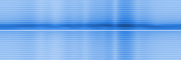
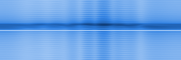
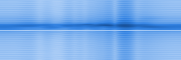
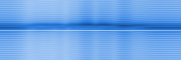
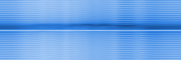
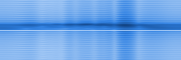
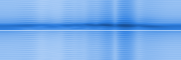
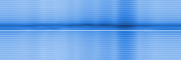
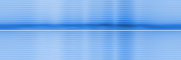
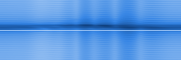
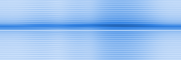
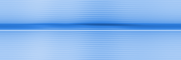
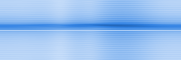
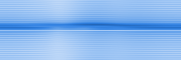
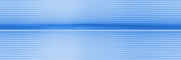
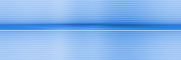
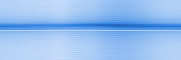
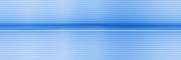
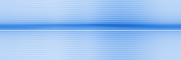
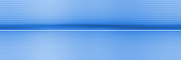

In [8]:
# Tokens: text in ink; identity = grey (low-error) vs orange (high-error), always with a label and shape.
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
GROUP_COLORS = {"low": INK_2, "high": "#eb6834"}
GROUP_SHAPES = {"low": "circle", "high": "diamond"}
GROUP_MARKERS = {"low": "o", "high": "D"}            # same shapes in matplotlib
GROUP_LABELS = [GROUP_LABEL["low"], GROUP_LABEL["high"]]
HM_W, HM_H = 362, 120          # 2 screen pixels per bin (181 azimuth × 60 Doppler bins)
CB_W = 14
PAIR_LABELS = list(pairs_df["pair_label"])

# One m/s-per-pixel scale for all three overview panels, so gaps can be compared directly.
_ranges = [frames_df["error"].max() * 1.1, np.ptp(frames_df["speed"]) * 1.3, np.ptp(frames_df["gt_vy"]) * 1.3]
SPAN = float(np.ceil(max(_ranges) / 0.02) * 0.02)


def centred(series, span=SPAN):
    mid = (series.min() + series.max()) / 2
    return [float(mid - span / 2), float(mid + span / 2)]


OVERVIEW = [  # field, panel title, x domain
    ("error", "2-D velocity error |pred − GT| (m/s)", [0.0, SPAN]),
    ("speed", "reference speed |GT| (m/s)", centred(frames_df["speed"])),
    ("gt_vy", "lateral GT velocity vy (m/s)", centred(frames_df["gt_vy"])),
]


# Card texts use the pre-formatted strings checked in section 4 (rounded once from full precision).
info_rows = []
for r in frames_df.itertuples():
    lines = [
        (f"{r.group_label} · frame {r.frame} · t = {r.time_s:.2f} s", True),
        (f"GT (vx, vy): {r.gt_vx_txt}, {r.gt_vy_txt} m/s", False),
        (f"Prediction (vx, vy): {r.pred_vx_txt}, {r.pred_vy_txt} m/s", False),
        (f"Reference speed |GT|: {r.speed_txt} m/s", False),
        (f"2-D error: {r.error_txt} m/s  (x {r.err_x_txt}, y {r.err_y_txt})", True),
    ]
    info_rows += [{"pair_id": r.pair_id, "card": r.group, "line": k, "text": t, "bold": b}
                  for k, (t, b) in enumerate(lines)]
for r in pairs_df.itertuples():
    lines = [
        ("Difference, high − low", True),
        (f"Δ reference speed: {r.d_speed_txt} m/s", False),
        (f"Δ GT vx: {r.d_gt_vx_txt} m/s", False),
        (f"Δ GT vy: {r.d_gt_vy_txt} m/s", False),
        (f"Δ 2-D error: {r.d_error_txt} m/s", True),
        (f"Recorded {abs(r.d_time_s):.1f} s apart", False),
    ]
    if not r.preferred:
        lines.append(("² lateral GT velocity differs more", False))
    info_rows += [{"pair_id": r.pair_id, "card": "diff", "line": k, "text": t, "bold": b}
                  for k, (t, b) in enumerate(lines)]
info_df = pd.DataFrame(info_rows)

dumbbell_df = pd.DataFrame([{
    "pair_label": lab, "field": f, "lo": float(g[f].min()), "hi": float(g[f].max())}
    for lab, g in frames_df.groupby("pair_label") for f, _, _ in OVERVIEW])

profile_rows = []
for i in range(len(frame)):
    for ch in CHANNELS:
        a = data[ch][i, 0].astype(np.float64)
        for kind, prof in (("doppler", a.mean(axis=1)), ("azimuth", a.mean(axis=0))):
            profile_rows.append({"pair_id": int(pair_id[i]), "group_label": GROUP_LABEL[group[i]], "frame": int(frame[i]),
                                 "channel": ch, "kind": kind, "bin": list(range(len(prof))),
                                 "value": [round(float(v), 4) for v in prof]})
profiles_df = pd.DataFrame(profile_rows)


def group_color():
    # Shared scale -> one legend for the whole page (merged with the shape legend; styled in configure_legend).
    return alt.Color("group_label:N", title=None, sort=GROUP_LABELS,
                     scale=alt.Scale(domain=GROUP_LABELS, range=[GROUP_COLORS["low"], GROUP_COLORS["high"]]))


def group_shape():
    return alt.Shape("group_label:N", title=None, sort=GROUP_LABELS,
                     scale=alt.Scale(domain=GROUP_LABELS, range=[GROUP_SHAPES["low"], GROUP_SHAPES["high"]]))


def make_explorer(title: str) -> alt.VConcatChart:
    pair = alt.selection_point(
        name="pair", fields=["pair_id"], value=DEFAULT_PAIR, on="click", clear=False, toggle=False,
        bind=alt.binding_select(options=[int(p) for p in pairs_df.pair_id], name="Frame pair: ",
                                labels=[lab.replace(" ²", " (larger lateral difference)") for lab in PAIR_LABELS]))
    only_pair = {"param": "pair", "empty": False}

    # --- Overview of all pairs ---------------------------------------------------------------
    def overview_panel(field, panel_title, domain, first):
        ticks = [round(float(t), 2) for t in np.arange(np.ceil(domain[0] / 0.04) * 0.04, domain[1] + 1e-9, 0.04)]
        x = alt.X(f"{field}:Q", title=panel_title, scale=alt.Scale(domain=domain, nice=False, zero=False),
                  axis=alt.Axis(values=ticks, format=".2f", titleFontWeight="normal"))
        y = alt.Y("pair_label:N", sort=PAIR_LABELS, title=None,
                  axis=alt.Axis(labels=first, ticks=False, domain=False, labelColor=INK, labelFontSize=11,
                                labelPadding=8) if first else None)
        band_base = alt.Chart(pairs_df).encode(y=y, x=alt.datum(domain[0]), x2=alt.datum(domain[1]))
        def points(grp, size):      # high-error diamonds first, low-error dots on top (visible when they overlap)
            # No tooltip here: the transparent row target on top receives the pointer (row tooltip + click).
            return alt.Chart(frames_df).transform_filter(alt.datum.group == grp).mark_point(
                filled=True, size=size, opacity=1, stroke=SURFACE, strokeWidth=1).encode(
                y=y, x=x, color=group_color(), shape=group_shape())

        zero = ([alt.Chart(pairs_df).mark_rule(color=AXIS, strokeWidth=1).encode(x=alt.datum(0.0))]
                if domain[0] < 0 < domain[1] else [])
        return alt.layer(
            band_base.transform_filter(only_pair).mark_rect(color=GRID, opacity=0.9),
            *zero,
            alt.Chart(dumbbell_df).transform_filter(alt.datum.field == field).mark_rule(color=AXIS, strokeWidth=2.5).encode(
                y=y, x=alt.X("lo:Q", title=panel_title, scale=alt.Scale(domain=domain, nice=False, zero=False)), x2="hi:Q"),
            points("high", 95),
            points("low", 70),
            band_base.mark_rect(opacity=0).encode(tooltip=[
                alt.Tooltip("pair_label:N", title="pair (click to show)"),
                alt.Tooltip("d_speed_txt:N", title="Δ speed (m/s)"),
                alt.Tooltip("d_gt_vy_txt:N", title="Δ GT vy (m/s)"),
                alt.Tooltip("d_error_txt:N", title="Δ 2-D error (m/s)")]).add_params(pair),
        ).properties(width=205, height=5 * 24)

    overview = alt.hconcat(*[overview_panel(f, t, d, k == 0) for k, (f, t, d) in enumerate(OVERVIEW)],
                           spacing=14).properties(title=alt.TitleParams(
        "All five pairs: click a row (or use the menu) to inspect it. All three panels use the same m/s per pixel, "
        "so the gaps can be compared directly.", fontSize=11, fontWeight="normal", color=INK_2, anchor="start"))

    # --- Text cards for the selected pair ------------------------------------------------------
    def card(which, width):
        base = alt.Chart(info_df).transform_filter(only_pair).transform_filter(alt.datum.card == which)
        y = alt.Y("line:O", scale=alt.Scale(domain=list(range(7))), axis=None)
        x0 = 16 if which != "diff" else 0
        layers = [
            base.transform_filter("!datum.bold").mark_text(align="left", baseline="middle", fontSize=11.5,
                                                            color=INK).encode(x=alt.value(x0), y=y, text="text:N"),
            base.transform_filter("datum.bold").mark_text(align="left", baseline="middle", fontSize=11.5,
                                                           fontWeight="bold", color=INK).encode(x=alt.value(x0), y=y, text="text:N"),
        ]
        if which != "diff":
            layers.insert(0, alt.Chart(frames_df).transform_filter(only_pair).transform_filter(
                alt.datum.group == which).mark_point(filled=True, size=90, opacity=1).encode(
                x=alt.value(5), y=alt.Y("lane:O", scale=alt.Scale(domain=list(range(7))), axis=None),
                color=group_color(), shape=group_shape()).transform_calculate(lane="0"))
        return alt.layer(*layers).properties(width=width, height=7 * 16)

    cards = alt.hconcat(card("low", HM_W), card("high", HM_W), card("diff", 210), spacing=12)

    # --- Heatmaps + colourbars -------------------------------------------------------------------
    def heatmap(ch, grp, bottom):
        left = grp == "low"
        return alt.Chart(images_df).transform_filter(only_pair).transform_filter(
            (alt.datum.channel == ch) & (alt.datum.group == grp)).mark_image(
            width=HM_W, height=HM_H, aspect=False, align="left", baseline="top", smooth=False).encode(
            x=alt.X("x0:Q", scale=alt.Scale(domain=[-0.5, 180.5], nice=False, zero=False),
                    axis=alt.Axis(values=[0, 30, 60, 90, 120, 150, 180], labels=bottom, ticks=True,
                                  title="azimuth bin" if bottom else None, grid=False)),
            y=alt.Y("y0:Q", scale=alt.Scale(domain=[-0.5, 59.5], reverse=True, nice=False, zero=False),
                    axis=alt.Axis(values=[0, 10, 20, 30, 40, 50, 59], labels=left, ticks=True, grid=False,
                                  title=[ch, "Doppler bin"] if left else None,
                                  titleFontWeight="bold" if left else "normal", titleColor=INK)),
            url="url:N",
        ).properties(width=HM_W, height=HM_H, view=alt.ViewBackground(stroke=AXIS, strokeWidth=1))

    def colorbar(ch):
        # One colourbar per channel: the scale is the same 0-1, but values are compared within a row only.
        return alt.Chart(colorbar_df).mark_image(
            width=CB_W, height=HM_H, aspect=False, align="left", baseline="top").encode(
            x=alt.X("cx:Q", scale=alt.Scale(domain=[0, 1]), axis=None),
            y=alt.Y("cy:Q", scale=alt.Scale(domain=list(COLOR_DOMAIN), nice=False, zero=False),
                    axis=alt.Axis(orient="right", values=[0, 0.25, 0.5, 0.75, 1], format=".2f",
                                  title=f"{ch} value", titleFontSize=10, grid=False)),
            url="url:N",
        ).properties(width=CB_W, height=HM_H, view=alt.ViewBackground(stroke=AXIS, strokeWidth=1))

    heat_rows = [alt.hconcat(heatmap(ch, "low", k == 1), heatmap(ch, "high", k == 1), colorbar(ch), spacing=12)
                 for k, ch in enumerate(CHANNELS)]

    # --- Profiles (means across one heatmap axis) ------------------------------------------------
    def profile(ch, kind, width):
        n_bins = 60 if kind == "doppler" else 181
        what = "mean over azimuth, per Doppler bin" if kind == "doppler" else "mean over Doppler, per azimuth bin"
        return alt.Chart(profiles_df).transform_filter(only_pair).transform_filter(
            (alt.datum.channel == ch) & (alt.datum.kind == kind)).transform_flatten(["bin", "value"]).mark_line(
            strokeWidth=1.8, point=alt.OverlayMarkDef(size=28, opacity=0)).encode(
            x=alt.X("bin:Q", title=f"{'Doppler' if kind == 'doppler' else 'azimuth'} bin",
                    scale=alt.Scale(domain=[0, n_bins - 1], nice=False)),
            y=alt.Y("value:Q", title=f"{ch} mean", scale=alt.Scale(domain=list(COLOR_DOMAIN)), axis=alt.Axis(tickCount=3)),
            color=group_color(), detail="frame:N",
            tooltip=[alt.Tooltip("group_label:N", title="frame type"), alt.Tooltip("frame:Q", title="frame"),
                     alt.Tooltip("bin:Q", title="bin"), alt.Tooltip("value:Q", title="mean value", format=".3f")],
        ).properties(width=width, height=90, title=alt.TitleParams(f"{ch}: {what}", fontSize=11,
                                                                   fontWeight="normal", color=INK_2, anchor="start"))

    profile_rows_ = [alt.hconcat(profile(ch, "doppler", 280), profile(ch, "azimuth", 470), spacing=24)
                     for ch in CHANNELS]

    chart = alt.vconcat(
        overview, cards, *heat_rows, *profile_rows_, spacing=18,
    ).properties(
        autosize=alt.AutoSizeParams(type="pad", resize=True),
        title=alt.TitleParams(title, anchor="start", fontSize=15, color=INK, subtitleColor=INK_2, subtitle=[
            "Five frame pairs at similar ground-truth speed: one low-error and one high-error frame each. "
            "Selected by error, so these are exploratory examples, not a representative sample.",
            "Heatmaps are the two model input channels as stored (rows: Doppler bins, columns: azimuth bins; "
            "bin indices, physical units not verified).",
            "Colour scale fixed at 0–1 within each channel, so both frames in a row are comparable. The channels are "
            "preprocessed differently: do not compare colours between rows.",
            "Values are rounded to 3 decimals from full precision; a 2-D error recomputed from rounded values can "
            "differ by 0.001 m/s.",
        ]),
    ).configure(background=SURFACE, font="system-ui, -apple-system, Segoe UI, sans-serif").configure_view(
        stroke=None).configure_axis(
        gridColor=GRID, domainColor=AXIS, tickColor=AXIS, labelColor=INK_2, titleColor=INK_2,
        labelFontSize=10, titleFontSize=11).configure_legend(
        orient="top", direction="horizontal", labelColor=INK, labelFontSize=11.5, symbolSize=90,
        symbolStrokeWidth=0)
    return chart


with warnings.catch_warnings():
    # The pair selection sits on all three overview panels on purpose; Altair notes that it merged them.
    warnings.filterwarnings("ignore", message="Automatically deduplicated selection parameter")
    explorer = make_explorer(f"Radar input & error explorer: {SEQUENCE} (transnet18, {SPLIT})")
explorer

## 8 · Save the interactive HTML (self-contained, opens offline)
The Vega, Vega-Lite and Vega-Embed JavaScript is embedded by `vl-convert-python`, so the file opens without internet (about 1.2 MB). The pinned version is checked again here.

**There is no fallback.** If the package is missing or has another version, this cell stops before writing anything, and an existing HTML stays unchanged.

The page is first written to a temporary file. It replaces the deliverable only if it:
- loads no external script or stylesheet,
- contains no CDN address,
- embeds the Vega-Lite bundle,
- embeds all 20 heatmap images.

The frame-pair menu is placed above the chart.

In [9]:
require_vl_convert()          # checked again right before export: no CDN fallback


def check_self_contained(html: str) -> list:
    # Problems that would make the page depend on the internet (an empty list means self-contained).
    problems = []
    if re.search(r"<script\b[^>]*\bsrc\s*=", html, flags=re.I):
        problems.append("an external <script src=...>")
    if re.search(r"<link\b[^>]*\bhref\s*=", html, flags=re.I):
        problems.append("an external <link href=...>")
    if "cdn.jsdelivr.net" in html:
        problems.append("a CDN address")
    if not re.search(r"vega-embed\.js bundle with Vega-Lite version v\d", html):
        problems.append("no embedded Vega-Lite bundle")
    n_img = html.count("data:image/png;base64,")
    if n_img < len(images_df):
        problems.append(f"only {n_img} embedded images (expected at least {len(images_df)})")
    return problems


# Page styling: menu above the chart, in the chart's font. Inserted right after the opening <head>,
# because the embedded Vega JavaScript itself contains the text "</head>".
css = ("<style>body{background:#fcfcfb;margin:16px}"
       "#vis .chart-wrapper{display:flex;flex-direction:column;align-items:flex-start}"
       ".vega-bindings{order:-1;font:14px system-ui,-apple-system,'Segoe UI',sans-serif;color:#0b0b0b;"
       "margin:0 0 12px 4px}.vega-bindings select{font:inherit;padding:2px 4px}</style>")

tmp = HTML_OUT.with_name(HTML_OUT.stem + ".tmp.html")
try:
    explorer.save(str(tmp), format="html", inline=True)
    html = tmp.read_text(encoding="utf-8")
    problems = check_self_contained(html)
    head = html.find("<head>")
    if head == -1:
        problems.append("no <head> element")
    if problems:
        raise RuntimeError("HTML export stopped, the page would not be self-contained: " + "; ".join(problems)
                           + f". {HTML_OUT.name} was not changed.")
    pos = head + len("<head>")
    tmp.write_text(html[:pos] + css + html[pos:], encoding="utf-8")
    os.replace(tmp, HTML_OUT)  # replace the deliverable only after all checks passed
finally:
    if tmp.exists():
        tmp.unlink()
print(f"saved (self-contained, opens offline, {HTML_OUT.stat().st_size / 1e6:.2f} MB):", HTML_OUT.relative_to(ROOT))

saved (self-contained, opens offline, 1.18 MB): results\phase1\main_0\bot_beckman_5thfloor_1_radar_error_explorer.html


## 9 · Static figure for the video (1920 × 1080 PNG)
The figure shows the selected pair (`STATIC_PAIR`, default 3) in detail and all five pairs in the overview, with the same colours, scale and encodings as the explorer.

saved: results\phase1\main_0\bot_beckman_5thfloor_1_radar_comparison.png


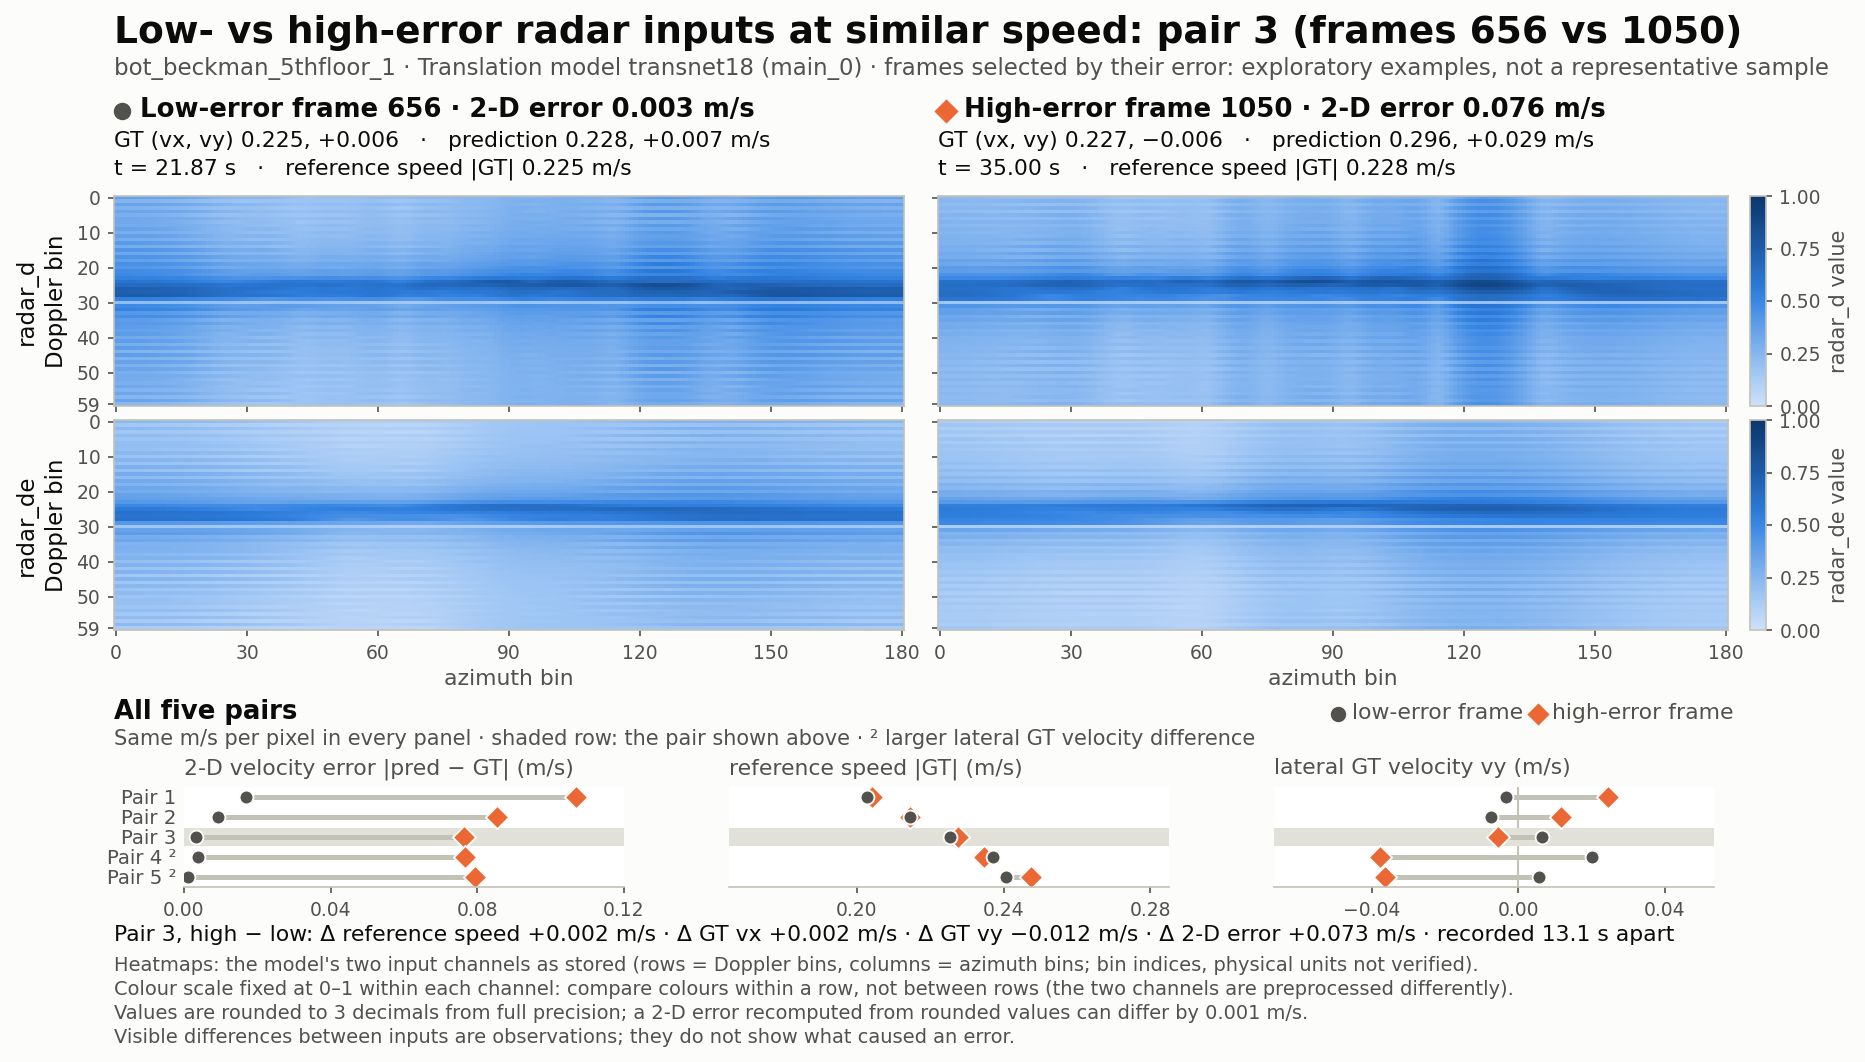

In [10]:
def static_figure(pid):
    W, H, DPI = 1920, 1080, 150
    plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": AXIS, "axes.labelcolor": INK_2,
                         "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK})
    fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor=SURFACE)

    def axes_px(x, y, w, h):          # (x, y) = top-left corner, in pixels from the figure's top-left
        return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])

    def text_px(x, y, s, **kw):       # y = text baseline, in pixels from the top
        return fig.text(x / W, 1 - y / H, s, va="baseline", **kw)

    def glyph_px(x, y, g, size=9):
        fig.add_artist(Line2D([x / W], [1 - y / H], ls="", marker=GROUP_MARKERS[g], markersize=size,
                              color=GROUP_COLORS[g], markeredgecolor=SURFACE, markeredgewidth=0.6,
                              transform=fig.transFigure))

    rows = {g: frames_df[(frames_df.pair_id == pid) & (frames_df.group == g)].iloc[0].to_dict() for g in ("low", "high")}
    prow = pairs_df[pairs_df.pair_id == pid].iloc[0].to_dict()
    L, HM_WPX, HM_HPX, COL_GAP = 125, 790, 210, 34
    col_x = [L, L + HM_WPX + COL_GAP]
    row_y = [205, 205 + HM_HPX + 14]
    right = col_x[1] + HM_WPX                       # right edge of the heatmap block

    # Title
    text_px(L, 52, f"Low- vs high-error radar inputs at similar speed: pair {pid} "
                   f"(frames {rows['low']['frame']} vs {rows['high']['frame']})", fontsize=18, fontweight="bold")
    text_px(L, 84, f"{SEQUENCE} · Translation model transnet18 ({SPLIT}) · frames selected by their error: "
                   "exploratory examples, not a representative sample", fontsize=11, color=INK_2)

    # Frame headers
    for c, g in enumerate(("low", "high")):
        r, x = rows[g], col_x[c]
        glyph_px(x + 8, 120, g)
        text_px(x + 26, 126, f"{r['group_label']} {r['frame']} · 2-D error {r['error_txt']} m/s",
                fontsize=12.5, fontweight="bold")
        text_px(x, 156, f"GT (vx, vy) {r['gt_vx_txt']}, {r['gt_vy_txt']}   ·   "
                        f"prediction {r['pred_vx_txt']}, {r['pred_vy_txt']} m/s", fontsize=10.5)
        text_px(x, 183, f"t = {r['time_s']:.2f} s   ·   reference speed |GT| {r['speed_txt']} m/s", fontsize=10.5)

    # Heatmaps (same RGB arrays as the HTML) and one colourbar per channel
    for k, ch in enumerate(CHANNELS):
        for c, g in enumerate(("low", "high")):
            ax = axes_px(col_x[c], row_y[k], HM_WPX, HM_HPX)
            ax.imshow(RGB[(ch, int(rows[g]["idx"]))], interpolation="nearest", aspect="auto",
                      extent=(-0.5, 180.5, 59.5, -0.5))
            ax.set_xticks([0, 30, 60, 90, 120, 150, 180]); ax.set_yticks([0, 10, 20, 30, 40, 50, 59])
            ax.tick_params(labelsize=9, length=3)
            if c == 0:
                ax.set_ylabel(f"{ch}\nDoppler bin", fontsize=11, color=INK, linespacing=1.4)
            else:
                ax.set_yticklabels([])
            if k == 1:
                ax.set_xlabel("azimuth bin", fontsize=10.5, labelpad=3)
            else:
                ax.set_xticklabels([])
        cax = axes_px(right + 22, row_y[k], 16, HM_HPX)
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(*COLOR_DOMAIN), cmap=CMAP), cax=cax,
                          ticks=[0, 0.25, 0.5, 0.75, 1])
        cb.ax.tick_params(labelsize=9, length=3); cb.outline.set_edgecolor(AXIS)
        cb.set_label(f"{ch} value", fontsize=10, color=INK_2)      # one colourbar per channel (row)

    # Overview strip: all five pairs, same m/s per pixel in all three panels
    oy = 728
    text_px(L, oy, "All five pairs", fontsize=12.5, fontweight="bold")
    text_px(L, oy + 26, "Same m/s per pixel in every panel · shaded row: the pair shown above · "
                        "² larger lateral GT velocity difference", fontsize=10, color=INK_2)
    lx = right - 390
    for g in ("low", "high"):
        glyph_px(lx, oy - 5, g, size=8)
        text_px(lx + 14, oy, GROUP_LABEL[g].lower(), fontsize=10.5, color=INK_2)
        lx += 200
    panel_w, panel_gap = 440, 105
    for j, (field, ptitle, domain) in enumerate(OVERVIEW):
        ax = axes_px(L + 70 + j * (panel_w + panel_gap), 796, panel_w, 100)
        if domain[0] < 0 < domain[1]:
            ax.axvline(0, color=AXIS, lw=1, zorder=0)
        for yy, p in enumerate(pairs_df.pair_id):
            if p == pid:
                ax.axhspan(yy - 0.45, yy + 0.45, color=GRID, zorder=0, lw=0)
            v = frames_df[frames_df.pair_id == p].set_index("group")[field]
            ax.plot([v["low"], v["high"]], [yy, yy], color=AXIS, lw=2.4, zorder=1, solid_capstyle="round")
            for g, size in (("high", 62), ("low", 44)):          # low-error dot on top where they overlap
                ax.scatter(v[g], yy, s=size, marker=GROUP_MARKERS[g], color=GROUP_COLORS[g], edgecolor=SURFACE,
                           linewidth=0.9, zorder=2)
        ax.set_xlim(domain); ax.set_ylim(len(pairs_df) - 0.5, -0.5)
        ax.set_yticks(range(len(pairs_df)))
        ax.set_yticklabels([f"Pair {p}" + ("" if p in PREFERRED_PAIRS else " ²") for p in pairs_df.pair_id]
                           if j == 0 else [], fontsize=9.5)
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=9, length=3)
        ax.xaxis.set_major_locator(mticker.MultipleLocator(0.04))
        ax.set_title(ptitle, fontsize=10.5, loc="left", color=INK_2, pad=6)
        for s in ("top", "right", "left"):
            ax.spines[s].set_visible(False)

    # Footer
    text_px(L, 950, f"Pair {pid}, high − low: Δ reference speed {prow['d_speed_txt']} m/s · Δ GT vx "
                    f"{prow['d_gt_vx_txt']} m/s · Δ GT vy {prow['d_gt_vy_txt']} m/s · Δ 2-D error "
                    f"{prow['d_error_txt']} m/s · recorded {abs(prow['d_time_s']):.1f} s apart", fontsize=10.5)
    for y, line in zip((980, 1004, 1028, 1052), (
            "Heatmaps: the model's two input channels as stored (rows = Doppler bins, columns = azimuth bins; "
            "bin indices, physical units not verified).",
            "Colour scale fixed at 0–1 within each channel: compare colours within a row, not between rows "
            "(the two channels are preprocessed differently).",
            "Values are rounded to 3 decimals from full precision; a 2-D error recomputed from rounded values "
            "can differ by 0.001 m/s.",
            "Visible differences between inputs are observations; they do not show what caused an error.")):
        text_px(L, y, line, fontsize=9.3, color=INK_2)
    return fig


fig = static_figure(STATIC_PAIR)
fig.savefig(PNG_OUT, dpi=150, facecolor=SURFACE)
print("saved:", PNG_OUT.relative_to(ROOT))
plt.show()

## 10 · Descriptive statistics of the inputs
Numbers behind visual impressions, per frame and channel:
- `median`, `p1`, `p99`: input values.
- `peak row`: the Doppler bin with the highest mean across azimuth.
- `dim row (20–40)`: the lowest-mean Doppler bin among rows 20–40, next to the band.
- `peak column`: the azimuth bin with the highest mean across Doppler.

These describe what is visible. They do not say what the model uses. Compare values within a channel only (section 5).

In [11]:
stat_rows = []
for r in frames_df.itertuples():
    for ch in CHANNELS:
        a = data[ch][r.idx, 0].astype(np.float64)
        rows_mean, cols_mean = a.mean(axis=1), a.mean(axis=0)
        stat_rows.append({"pair_id": r.pair_id, "group": r.group, "frame": r.frame, "channel": ch,
                          "median": np.median(a), "p1": np.percentile(a, 1), "p99": np.percentile(a, 99),
                          "max": a.max(), "peak row": int(rows_mean.argmax()),
                          "dim row (20–40)": int(20 + rows_mean[20:41].argmin()),
                          "peak column": int(cols_mean.argmax())})
stats = pd.DataFrame(stat_rows)
display(stats.round(3))

wide = stats.pivot_table(index="pair_id", columns=["channel", "group"], values="median")
diff = pd.DataFrame({f"Δ median {ch} (high − low)": wide[(ch, "high")] - wide[(ch, "low")] for ch in CHANNELS})
display(diff.round(3))

,pair_id,group,frame,channel,median,p1,p99,max,peak row,dim row (20–40),peak column
0,1,low,192,radar_d,0.250,0.128,0.685,0.839,26,30,125
1,1,low,192,radar_de,0.152,0.029,0.622,0.692,26,30,118
2,1,high,386,radar_d,0.309,0.177,0.769,0.956,24,30,103
3,1,high,386,radar_de,0.199,0.094,0.650,0.782,24,30,101
4,2,low,1681,radar_d,0.249,0.136,0.676,0.812,25,30,125
5,2,low,1681,radar_de,0.157,0.049,0.598,0.685,25,30,121
6,2,high,667,radar_d,0.308,0.165,0.745,0.831,25,30,124
7,2,high,667,radar_de,0.199,0.076,0.626,0.690,25,30,99
8,3,low,656,radar_d,0.320,0.168,0.755,0.846,25,30,152
9,3,low,656,radar_de,0.218,0.079,0.639,0.678,25,30,139


,Δ median radar_d (high − low),Δ median radar_de (high − low)
pair_id,,
1,0.058,0.047
2,0.059,0.042
3,-0.022,-0.005
4,0.037,0.044
5,0.155,0.164


## 11 · Observations and open hypotheses
These statements cover only the 10 frames above.
- The pairs were **selected by their errors**, so they are exploratory examples, not a representative sample.
- Nothing here shows what caused an error or which input regions the model uses.
- The cell below recomputes every number and stops if a statement no longer holds.

**Observations** (measured in this notebook):
1. **Matching.**
   - Within a pair, the GT speed differs by at most 0.007 m/s, and by less than 0.003 m/s in pairs 1–4.
   - Lateral GT velocity differs by 0.012–0.028 m/s in pairs 1–3 and by 0.042–0.058 m/s in pairs 4–5.
   - The error gap (high − low) is +0.073 to +0.090 m/s.
   - The two frames of a pair are 4.2–33.8 s apart.
2. **Direction of the error.**
   - In pairs 1–4 the high-error frame over-predicts vx: prediction 0.272–0.310 m/s, GT 0.203–0.232 m/s.
   - In pair 5 it under-predicts vx (0.202 vs 0.245 m/s), and its lateral error is +0.067 m/s.
3. **Predicted vy.** In all five high-error frames the predicted vy is +0.025 to +0.031 m/s, while GT vy ranges from −0.038 to +0.025 m/s.
4. **Overall input level.**
   - In pairs 1, 2, 4 and 5 the high-error frame has the higher median input value in both channels: Δ median +0.037 to +0.155 in `radar_d` and +0.042 to +0.164 in `radar_de`.
   - Pair 3 is the exception (−0.022 and −0.005).
   - Each difference compares two frames of the same channel.
5. **Shared structure.**
   - In all 10 frames and both channels, the Doppler profile peaks at rows 24–27. Its minimum within rows 20–40 is row 30.
   - In `radar_d`, the azimuth column with the highest mean is 124–127 in 8 of 10 frames (frame 386: 103, frame 656: 152).
   - In `radar_de` the peak column varies more (99–139).

**Explained by the preprocessing** (derived from the code in section 5, not measured here): row 30 is the zero-Doppler row, which the mean subtraction over chirps removes before the log. Its low values are therefore expected in every frame, low-error and high-error alike.

**Open hypotheses** (not tested here):
- **H1:** the overall input level is related to the error. Pair 3 already runs against a simple version of this. A test needs all 1,798 frames, but the prepared input NPZ with every frame is not in the repository.
- **H2:** the larger lateral GT differences in pairs 4–5 contribute to their error gaps. Separating this effect would need pairs matched on both vx and vy.

In [12]:
# Recompute every number stated in section 11 (fmt rounds once from full precision; "−" is U+2212).
lo_ = frames_df[frames_df.group == "low"].set_index("pair_id").sort_index()
hi_ = frames_df[frames_df.group == "high"].set_index("pair_id").sort_index()
pp = pairs_df.set_index("pair_id").sort_index()
d_med = {ch: diff[f"Δ median {ch} (high − low)"] for ch in CHANNELS}
P14, P13, P45, P1245 = [1, 2, 3, 4], [1, 2, 3], [4, 5], [1, 2, 4, 5]


def span(values, signed=False, sep="–"):
    v = list(values)
    return f"{fmt(min(v), signed)}{sep}{fmt(max(v), signed)}"


pc_d = stats[stats.channel == "radar_d"].set_index("frame")["peak column"]
pc_de = stats[stats.channel == "radar_de"].set_index("frame")["peak column"]
inside = pc_d.between(124, 127)
outside = {int(f): int(c) for f, c in pc_d[~inside].items()}
dt = pp.d_time_s.abs()

claims = [  # (observation, statement, recomputed, holds)
    (1, "|Δ speed| ≤ 0.007 m/s in every pair", fmt(pp.d_speed.abs().max()), pp.d_speed.abs().max() <= 0.007),
    (1, "|Δ speed| < 0.003 m/s in pairs 1–4", fmt(pp.d_speed.abs()[P14].max()), pp.d_speed.abs()[P14].max() < 0.003),
    (1, "|Δ GT vy| 0.012–0.028 m/s in pairs 1–3", span(pp.d_gt_vy.abs()[P13]), span(pp.d_gt_vy.abs()[P13]) == "0.012–0.028"),
    (1, "|Δ GT vy| 0.042–0.058 m/s in pairs 4–5", span(pp.d_gt_vy.abs()[P45]), span(pp.d_gt_vy.abs()[P45]) == "0.042–0.058"),
    (1, "Δ error +0.073 to +0.090 m/s", span(pp.d_error, True, " to "), span(pp.d_error, True, " to ") == "+0.073 to +0.090"),
    (1, "frames 4.2–33.8 s apart", f"{dt.min():.1f}–{dt.max():.1f}", f"{dt.min():.1f}–{dt.max():.1f}" == "4.2–33.8"),
    (2, "pairs 1–4: high-error frame over-predicts vx", span(hi_.err_x[P14], True, " to "), bool((hi_.err_x[P14] > 0).all())),
    (2, "pairs 1–4: predicted vx 0.272–0.310 m/s", span(hi_.pred_vx[P14]), span(hi_.pred_vx[P14]) == "0.272–0.310"),
    (2, "pairs 1–4: GT vx 0.203–0.232 m/s", span(hi_.gt_vx[P14]), span(hi_.gt_vx[P14]) == "0.203–0.232"),
    (2, "pair 5: predicted vx 0.202, GT vx 0.245, lateral error +0.067 m/s",
     ", ".join([hi_.pred_vx_txt[5], hi_.gt_vx_txt[5], hi_.err_y_txt[5]]),
     (hi_.pred_vx_txt[5], hi_.gt_vx_txt[5], hi_.err_y_txt[5]) == ("0.202", "0.245", "+0.067")),
    (3, "high-error frames: predicted vy +0.025 to +0.031 m/s", span(hi_.pred_vy, True, " to "),
     span(hi_.pred_vy, True, " to ") == "+0.025 to +0.031"),
    (3, "high-error frames: GT vy −0.038 to +0.025 m/s", span(hi_.gt_vy, True, " to "),
     span(hi_.gt_vy, True, " to ") == "−0.038 to +0.025"),
    (4, "Δ median radar_d +0.037 to +0.155 (pairs 1, 2, 4, 5)", span(d_med["radar_d"][P1245], True, " to "),
     span(d_med["radar_d"][P1245], True, " to ") == "+0.037 to +0.155"),
    (4, "Δ median radar_de +0.042 to +0.164 (pairs 1, 2, 4, 5)", span(d_med["radar_de"][P1245], True, " to "),
     span(d_med["radar_de"][P1245], True, " to ") == "+0.042 to +0.164"),
    (4, "pair 3: Δ median −0.022 (radar_d), −0.005 (radar_de)",
     ", ".join(fmt(d_med[ch][3], True) for ch in CHANNELS),
     tuple(fmt(d_med[ch][3], True) for ch in CHANNELS) == ("−0.022", "−0.005")),
    (5, "peak row 24–27 (all frames, both channels)", f"{stats['peak row'].min()}–{stats['peak row'].max()}",
     f"{stats['peak row'].min()}–{stats['peak row'].max()}" == "24–27"),
    (5, "minimum within rows 20–40 at row 30 (all frames, both channels)", str(sorted(set(stats["dim row (20–40)"]))),
     set(stats["dim row (20–40)"]) == {30}),
    (5, "radar_d peak column 124–127 in 8 of 10 frames (386: 103, 656: 152)",
     f"{int(inside.sum())} of {len(pc_d)}; others {outside}", int(inside.sum()) == 8 and outside == {386: 103, 656: 152}),
    (5, "radar_de peak column 99–139", f"{pc_de.min()}–{pc_de.max()}", f"{pc_de.min()}–{pc_de.max()}" == "99–139"),
]
claims_df = pd.DataFrame(claims, columns=["obs.", "statement", "recomputed", "holds"])
claims_df["holds"] = claims_df["holds"].map({True: "PASS", False: "FAIL"})
display(claims_df)
if (claims_df["holds"] == "FAIL").any():
    raise AssertionError("a statement in section 11 no longer matches the data; update the text")
print(f"All {len(claims_df)} statements in section 11 match the data.")

,obs.,statement,recomputed,holds
0,1,|Δ speed| ≤ 0.007 m/s in every pair,0.007,PASS
1,1,|Δ speed| < 0.003 m/s in pairs 1–4,0.002,PASS
2,1,|Δ GT vy| 0.012–0.028 m/s in pairs 1–3,0.012–0.028,PASS
3,1,|Δ GT vy| 0.042–0.058 m/s in pairs 4–5,0.042–0.058,PASS
4,1,Δ error +0.073 to +0.090 m/s,+0.073 to +0.090,PASS
5,1,frames 4.2–33.8 s apart,4.2–33.8,PASS
6,2,pairs 1–4: high-error frame over-predicts vx,+0.041 to +0.107,PASS
7,2,pairs 1–4: predicted vx 0.272–0.310 m/s,0.272–0.310,PASS
8,2,pairs 1–4: GT vx 0.203–0.232 m/s,0.203–0.232,PASS
9,2,"pair 5: predicted vx 0.202, GT vx 0.245, later...","0.202, 0.245, +0.067",PASS


All 19 statements in section 11 match the data.


## 12 · Verification checklist (manual)
1. **Validation table (section 2):** every row is PASS. The predictions cross-check is PASS, or SKIPPED only if the predictions file is missing.
2. **Rounding (section 4):** all displayed numbers are correctly rounded. For pair 3's high-error frame (1050), |prediction − GT| = 0.07649239 m/s is shown as 0.076 m/s in the table, the card and the PNG header. Recomputed from the displayed velocities it gives 0.077, which is a rounding effect only.
3. **Colour scale (section 5):**
   - `COLOR_DOMAIN` is the only scale used by `to_rgb`, the colourbars and the PNG.
   - Each row's colourbar is labelled with its channel (`radar_d value`, `radar_de value`) and reads 0–1.
   - Colours are compared within a row only.
   - A heatmap pixel's colour matches `to_rgb(value)` for its bin (e.g. compare `RGB[("radar_d", 0)][30, 90]` with `to_rgb(data["radar_d"][0, 0, 30, 90])`).
4. **Explorer:**
   - Pair 3 opens first.
   - Each menu choice and each overview click updates the cards, heatmaps and profiles, and the frame numbers match section 3.
   - Pairs 4–5 carry the "larger lateral difference" note.
5. **Outputs:**
   - The HTML is about 1.2 MB and opens with the network switched off.
   - The PNG is 1920 × 1080.
6. **Observations (section 11):** every statement is PASS.